# Team12 Toxicity Detection — качество модели и применимость для модерации

**Объект оценки:** сохранённая baseline-модель `Logistic Regression` (`TF-IDF`, классы `neutral / offensive / toxic`) и её использование в конечном проекте FastAPI + PostgreSQL + MLflow + Prometheus/Grafana.

**Задача оценки:** определить не только качество трёхклассовой классификации, но и риск неправомерного скрытия нейтральных сообщений при разных политиках модерации.

**Основной вывод:** модель пригодна как **прототип классификатора и инструмент поддержки модератора**. Автоматическое скрытие всех предсказанных `toxic`/`offensive` без порога, ручной проверки и механизма обжалования не рекомендуется.

В ноутбуке использованы агрегированные показатели исходного тестового набора (35 985 записей) и отдельный пересчёт порогов на исходной baseline-модели. Тексты комментариев **не публикуются**. Расчёт порогов является дополнительным офлайн-анализом, а не уже внедрённым правилом API.

## 1. Задача и граница применения

Система принимает текст сообщения и возвращает одну из трёх меток с оценками вероятностей. Типовые сценарии: предварительная сортировка сообщений, приоритизация ручной модерации и анализ тенденций. Важно отличать **классификацию** от **действия модерации**: текущий `POST /predict` возвращает `label`, `probabilities` и `model`, но **не удаляет и не скрывает сообщения**.

В бизнес-постановке есть две противоположные ошибки:

- **False negative:** угрожающий комментарий ошибочно признан безопасным — вредное сообщение остаётся видимым.
- **False positive на нейтральном контенте:** нормальный комментарий ошибочно скрывается — страдает доверие пользователей и свобода общения.

Для внедрения правила скрытия должны учитывать цену обеих ошибок, частоту реальной токсичности, возможность апелляции и требования к скорости реакции. Ни одного универсального «достаточного Macro-F1» для такой задачи не существует.

## 2. Что реально означают классы

| Исходная метка | Класс модели | Смысл для модерации |
|---|---|---|
| `NORMAL` | `neutral` | Нейтральный комментарий |
| `INSULT`, `OBSCENITY` | `offensive` | Оскорбление или ненормативная лексика |
| `THREAT` | `toxic` | Угроза (специфичный, более узкий класс) |

Это **многоклассовая** постановка, а не готовая бинарная метка «можно / нельзя публиковать». Ошибочно считать, что `toxic` охватывает все виды токсичности, а `offensive` всегда требует удаления: допустимость содержания зависит от правил платформы и контекста.

По исходному одно-меточному парсеру 8 333 многометочные записи не вошли в оценку; это отдельный риск качества на смешанных ситуациях (угроза плюс оскорбление). До очистки 248 290 строк, после одно-меточного парсинга 239 957; после нормализации, удаления дубликатов/конфликтов 239 900.

## 3. Источники, воспроизводимость и статус «финальной» модели

- `reports/baseline_real_dataset_evaluation.json` и `artifacts/test_report.csv`: сохранённые агрегированные результаты baseline.
- `artifacts/baseline_model.joblib` и `artifacts/baseline_metadata.json`: исходная модель и seed=42.
- `mlops/data.py`: отображение классов, нормализация и воспроизведение разбиения **70/15/15**.
- `reports/01_quality_evaluation_executed_on_real_dataset.ipynb`: повторный расчёт baseline по реальному тесту.
- Локальные результаты MLflow: пять runs (исходный baseline, три кандидата и champion Logistic Regression); для champion на Mac `test_macro_f1=0.857168623`, `test_toxic_recall=0.880341880`, то есть **те же значения**, что у baseline. Кандидат автоматически **не развёрнут** вместо исходной модели.

**Граница доказательств:** матрица ошибок ниже принадлежит именно **baseline**, для которого есть сохранённый результат по всем 35 985 записям. Одинаковый Macro-F1 у champion не доказывает идентичность его ошибок по классам и не позволяет переносить на него нижеприведённые показатели ложного скрытия без отдельного пересчёта.

**Совместимость:** исходный joblib сериализован с `scikit-learn 1.9.1`. Дополнительные таблицы порогов ниже пересчитаны в доступной офлайн-среде с `scikit-learn 1.8.0`. Поэтому их следует подтвердить в закреплённом окружении проекта перед релизом правил модерации.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CLASSES = ('neutral', 'offensive', 'toxic')
CM = np.array([[29333, 1006, 208],
               [  652, 3889,  78],
               [   50,   48, 721]], dtype=int)
RECORDED = {'accuracy': 0.9432541336668057,
            'macro_f1': 0.8571686229984659,
            'toxic_recall': 0.8803418803418803}
DATASET_SHA256 = '426e6bd2514fb974b68c3794da6862f5c67a34f32bdd41efeb5266a101048381'

assert CM.sum() == 35985
assert list(CM.sum(axis=1)) == [30547, 4619, 819]
print('Тестовых записей:', CM.sum())
print('Исходный хеш датасета:', DATASET_SHA256)

Тестовых записей: 35985
Исходный хеш датасета: 426e6bd2514fb974b68c3794da6862f5c67a34f32bdd41efeb5266a101048381


## 4. Состав тестовой выборки и дисбаланс

Из **35 985** тестовых сообщений **30 547 — neutral (84,9%)**, **4 619 — offensive (12,8%)**, **819 — toxic (2,3%)**. На таком дисбалансе высокая Accuracy может скрывать ошибки редкого класса. Поэтому важно смотреть Macro-F1, Recall, Precision и ошибки нейтрального класса отдельно.

,count,share_%
neutral,30547,84.89
offensive,4619,12.84
toxic,819,2.28


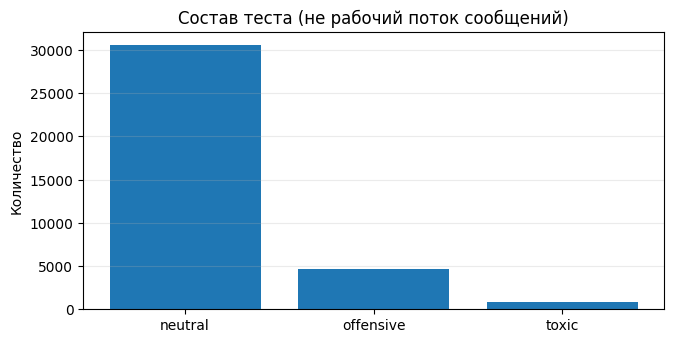

In [2]:
class_counts = pd.Series(CM.sum(axis=1), index=CLASSES, name='support')
display(pd.DataFrame({'count':class_counts, 'share_%':(100*class_counts/CM.sum()).round(2)}))
fig, ax = plt.subplots(figsize=(7.5,3.6))
ax.bar(CLASSES, class_counts.values)
ax.set_title('Состав теста (не рабочий поток сообщений)')
ax.set_ylabel('Количество')
ax.grid(axis='y',alpha=.25)
plt.show()

## 5. Итоговые метрики baseline

**Accuracy** — доля правильно определённых сообщений, но при дисбалансе её недостаточно. **Precision** показывает долю правильных срабатываний среди предсказаний класса. **Recall** показывает, какую долю истинных сообщений данного класса модель нашла. **F1** — гармоническое среднее Precision и Recall; **Macro-F1** одинаково учитывает каждый класс.

Одна и та же модель может иметь высокий Recall `toxic` и при этом достаточно большой риск ошибочного скрытия нормального контента.

In [3]:
precision = np.diag(CM) / CM.sum(axis=0)
recall = np.diag(CM) / CM.sum(axis=1)
f1 = 2*precision*recall / (precision+recall)
class_report = pd.DataFrame({'Precision':precision,'Recall':recall,'F1':f1,'Support':CM.sum(axis=1)},index=CLASSES)
display(class_report.round(4))
acc = np.trace(CM)/CM.sum()
macro_f1 = np.mean(f1)
weighted_f1 = np.average(f1,weights=CM.sum(axis=1))
print(f'Accuracy: {acc:.6f} ({acc:.2%})')
print(f'Macro-F1: {macro_f1:.6f}')
print(f'Weighted-F1: {weighted_f1:.6f}')
assert np.isclose(acc,RECORDED['accuracy']) and np.isclose(macro_f1,RECORDED['macro_f1'])

,Precision,Recall,F1,Support
neutral,0.9766,0.9603,0.9684,30547
offensive,0.7868,0.8420,0.8134,4619
toxic,0.7160,0.8803,0.7897,819


Accuracy: 0.943254 (94.33%)
Macro-F1: 0.857169
Weighted-F1: 0.944418


## 6. Матрица ошибок — ключ к политике скрытия

**Строки** — истинный класс, **столбцы** — предсказание модели. Например, число **208** на пересечении `neutral → toxic` — это 208 действительно нейтральных сообщений, которые будут ошибочно скрыты при безусловном скрытии всех предсказаний `toxic`.

,Прогноз: neutral,Прогноз: offensive,Прогноз: toxic
Факт: neutral,29333,1006,208
Факт: offensive,652,3889,78
Факт: toxic,50,48,721


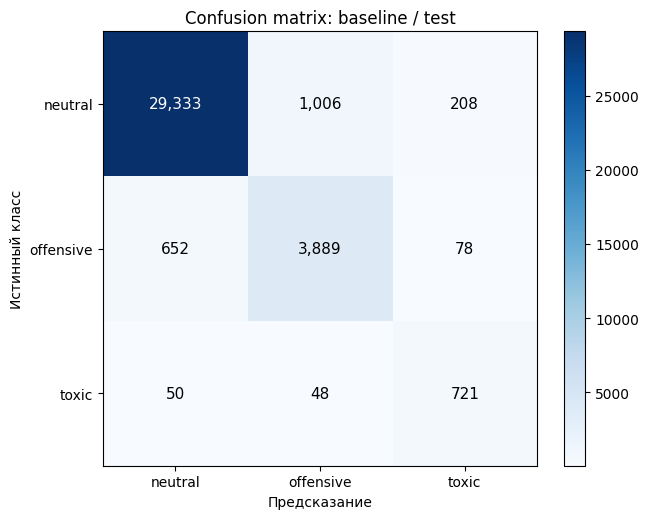

In [4]:
cm_frame=pd.DataFrame(CM,index=[f'Факт: {x}' for x in CLASSES],columns=[f'Прогноз: {x}' for x in CLASSES])
display(cm_frame)
fig, ax=plt.subplots(figsize=(7.4,5.3))
im=ax.imshow(CM,cmap='Blues')
ax.set_xticks(range(3),labels=CLASSES)
ax.set_yticks(range(3),labels=CLASSES)
ax.set_xlabel('Предсказание'); ax.set_ylabel('Истинный класс')
ax.set_title('Confusion matrix: baseline / test')
for (i,j),val in np.ndenumerate(CM):
    ax.text(j,i,format(val,','),ha='center',va='center',color='white' if val>CM.max()/2 else 'black',fontsize=11)
fig.colorbar(im,ax=ax,fraction=.045,pad=.04)
plt.tight_layout();plt.show()

## 7. Две возможные политики скрытия

**A. Скрывать только предсказанный `toxic`.** Эта политика ориентирована прежде всего на угрозы. Она *не* скрывает оскорбления, если модель пометила их как `offensive`.

**B. Скрывать оба класса `offensive` и `toxic`.** Она охватывает больше нежелательного контента, но существенно увеличивает число ошибочно скрытых нейтральных сообщений.

Метрики этих политик считаются прямо по матрице ошибок, а не выводятся из Accuracy или общего Macro-F1.

In [5]:
neutral_count=CM[0].sum()
threat_count=CM[2].sum()
harmful_count=CM[1:].sum()

hide_toxic=CM[:,2].sum()
false_neutral_toxic=CM[0,2]
caught_threat_toxic=CM[2,2]

hide_both=CM[:,1:].sum()
false_neutral_both=CM[0,1:].sum()
caught_harmful_both=CM[1:,1:].sum()
caught_threat_both=CM[2,1:].sum()

policies=pd.DataFrame([
 {'Политика':'Скрывать только toxic', 'Всего скрыто':hide_toxic,
  'Ошибочно скрыто neutral':false_neutral_toxic,
  'FPR на neutral':false_neutral_toxic/neutral_count,
  'Найдено угроз (из 819)':caught_threat_toxic,
  'Recall угроз':caught_threat_toxic/threat_count,
  'Precision на threat':caught_threat_toxic/hide_toxic},
 {'Политика':'Скрывать offensive + toxic', 'Всего скрыто':hide_both,
  'Ошибочно скрыто neutral':false_neutral_both,
  'FPR на neutral':false_neutral_both/neutral_count,
  'Найдено угроз (из 819)':caught_threat_both,
  'Recall угроз':caught_threat_both/threat_count,
  'Precision на threat':caught_threat_both/hide_both},
])
display(policies.round(4))
print(f'Скрывать только toxic: ложное скрытие neutral = {false_neutral_toxic}/{neutral_count} = {false_neutral_toxic/neutral_count:.2%}; пропущено угроз {threat_count-caught_threat_toxic}/{threat_count}.')
print(f'Скрывать оба класса: ложное скрытие neutral = {false_neutral_both}/{neutral_count} = {false_neutral_both/neutral_count:.2%}.')
print(f'Для политики "оба класса": корректно найдено offensive или toxic {caught_harmful_both}/{harmful_count} = {caught_harmful_both/harmful_count:.2%}.')

,Политика,Всего скрыто,Ошибочно скрыто neutral,FPR на neutral,Найдено угроз (из 819),Recall угроз,Precision на threat
0,Скрывать только toxic,1007,208,0.0068,721,0.8803,0.7160
1,Скрывать offensive + toxic,5950,1214,0.0397,769,0.9389,0.1292


Скрывать только toxic: ложное скрытие neutral = 208/30547 = 0.68%; пропущено угроз 98/819.
Скрывать оба класса: ложное скрытие neutral = 1214/30547 = 3.97%.
Для политики "оба класса": корректно найдено offensive или toxic 4736/5438 = 87.09%.


**Интерпретация по типам ошибок**

- При скрытии только `toxic`: из **1 007** автоматически скрытых сообщений **721** на самом деле имеют метку `toxic`, **78 — offensive**, **208 — neutral**. Таким образом, **28,4%** скрытий не являются точными попаданиями в класс угроз, но из них именно **20,7% всех скрытий — нейтральные сообщения**. Здесь нельзя приравнивать `offensive` к полностью безвредному содержанию.
- При скрытии `offensive` и `toxic`: скрывается **5 950** сообщений, среди них **1 214 нейтральных**. Для массового потока это ощутимый риск чрезмерной модерации.
- Если система должна удалять **только угрозы**, существенен Recall класса `toxic`. Если она должна ограничивать **и угрозы, и оскорбления**, требуется отдельная бинарная оценка объединённого класса и правило допуска разных типов контента.

## 8. Насколько надёжны доли ошибок?

Доли вычислены на конкретном holdout-наборе. Для ориентира рассчитаем **95%-е интервалы Уилсона** для вероятностей ошибочного скрытия нейтрального сообщения и обнаружения угроз. Они показывают только неопределённость измерения **при условии независимой репрезентативной выборки**; сдвиг распределения, ошибки разметки и изменение правил платформы ими не учитываются.

In [6]:
def wilson_interval(successes, n, z=1.95996398454):
    p=successes/n
    d=1+z*z/n
    center=(p+z*z/(2*n))/d
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/d
    return center-half,center+half

intervals=[]
for label,k,n in [
    ('neutral ошибочно скрыто: только toxic',CM[0,2],neutral_count),
    ('neutral ошибочно скрыто: оба класса',CM[0,1:].sum(),neutral_count),
    ('recall угроз при скрытии toxic',CM[2,2],threat_count),
]:
    lo,hi=wilson_interval(k,n)
    intervals.append({'Показатель':label,'Выборка':f'{k}/{n}','Оценка':f'{k/n:.2%}',
                      '95% интервал (условно)':f'{lo:.2%} – {hi:.2%}'})
display(pd.DataFrame(intervals))

,Показатель,Выборка,Оценка,95% интервал (условно)
0,neutral ошибочно скрыто: только toxic,208/30547,0.68%,0.59% – 0.78%
1,neutral ошибочно скрыто: оба класса,1214/30547,3.97%,3.76% – 4.20%
2,recall угроз при скрытии toxic,721/819,88.03%,85.63% – 90.08%


## 9. Почему одного класса недостаточно: порог уверенности

Сейчас `ModelService.predict()` выбирает класс с максимальной `predict_proba`. В API **не встроено правило скрытия по порогу**. Можно отдельно исследовать предлагаемую политику:

`auto_hide ⇔ predicted_label == "toxic" AND P(toxic) >= threshold`

Остальные предсказанные `toxic` можно передавать модератору, а не автоматически оставлять в публичном доступе. Значение вероятности **не следует трактовать как гарантированную вероятность правоты**, пока калибровка не проверена.

Далее — **офлайн-таблица**, рассчитанная по исходной baseline-модели на validation и test, без публикации текстов. Пересчёт произведён с `sklearn 1.8.0`, тогда как релизный артефакт создан под `1.9.1`: для внедрения нужно воспроизвести таблицу в закреплённом окружении. Пороговые цифры пока **не относятся к текущему production/API-поведению**.

In [7]:
THRESHOLD_TABLES = {'validation': {'n': 35985,
                'classes': {'neutral': 30547, 'offensive': 4619, 'toxic': 819},
                'confusion_matrix': [[29254, 1025, 268], [650, 3896, 73], [44, 43, 732]],
                'thresholds': [{'threshold': 0.0,
                                'auto_hide_count': 1073,
                                'neutral_false_hidden': 268,
                                'neutral_fpr': 0.0087734,
                                'toxic_caught': 732,
                                'toxic_recall': 0.8937729,
                                'auto_hide_precision_threat': 0.6821994,
                                'offensive_hidden': 73},
                               {'threshold': 0.3,
                                'auto_hide_count': 1073,
                                'neutral_false_hidden': 268,
                                'neutral_fpr': 0.0087734,
                                'toxic_caught': 732,
                                'toxic_recall': 0.8937729,
                                'auto_hide_precision_threat': 0.6821994,
                                'offensive_hidden': 73},
                               {'threshold': 0.4,
                                'auto_hide_count': 1054,
                                'neutral_false_hidden': 252,
                                'neutral_fpr': 0.0082496,
                                'toxic_caught': 730,
                                'toxic_recall': 0.8913309,
                                'auto_hide_precision_threat': 0.6925996,
                                'offensive_hidden': 72},
                               {'threshold': 0.5,
                                'auto_hide_count': 966,
                                'neutral_false_hidden': 188,
                                'neutral_fpr': 0.0061545,
                                'toxic_caught': 716,
                                'toxic_recall': 0.8742369,
                                'auto_hide_precision_threat': 0.7412008,
                                'offensive_hidden': 62},
                               {'threshold': 0.6,
                                'auto_hide_count': 849,
                                'neutral_false_hidden': 121,
                                'neutral_fpr': 0.0039611,
                                'toxic_caught': 690,
                                'toxic_recall': 0.8424908,
                                'auto_hide_precision_threat': 0.8127208,
                                'offensive_hidden': 38},
                               {'threshold': 0.7,
                                'auto_hide_count': 763,
                                'neutral_false_hidden': 80,
                                'neutral_fpr': 0.0026189,
                                'toxic_caught': 658,
                                'toxic_recall': 0.8034188,
                                'auto_hide_precision_threat': 0.8623853,
                                'offensive_hidden': 25},
                               {'threshold': 0.75,
                                'auto_hide_count': 710,
                                'neutral_false_hidden': 54,
                                'neutral_fpr': 0.0017678,
                                'toxic_caught': 636,
                                'toxic_recall': 0.7765568,
                                'auto_hide_precision_threat': 0.8957746,
                                'offensive_hidden': 20},
                               {'threshold': 0.8,
                                'auto_hide_count': 675,
                                'neutral_false_hidden': 44,
                                'neutral_fpr': 0.0014404,
                                'toxic_caught': 613,
                                'toxic_recall': 0.7484737,
                                'auto_hide_precision_threat': 0.9081481,
                                'offensive_hidden': 18},
                               {'threshold': 0.85,
                                'auto_hide_count': 624,
                                'neutral_false_hidden': 30,
                                'neutral_fpr': 0.0009821,
                                'toxic_caught': 580,
                                'toxic_recall': 0.7081807,
                                'auto_hide_precision_threat': 0.9294872,
                                'offensive_hidden': 14},
                               {'threshold': 0.9,
                                'auto_hide_count': 565,
                                'neutral_false_hidden': 23,
                                'neutral_fpr': 0.0007529,
                                'toxic_caught': 534,
                                'toxic_recall': 0.6520147,
                                'auto_hide_precision_threat': 0.9451327,
                                'offensive_hidden': 8},
                               {'threshold': 0.95,
                                'auto_hide_count': 485,
                                'neutral_false_hidden': 11,
                                'neutral_fpr': 0.0003601,
                                'toxic_caught': 469,
                                'toxic_recall': 0.5726496,
                                'auto_hide_precision_threat': 0.9670103,
                                'offensive_hidden': 5},
                               {'threshold': 0.98,
                                'auto_hide_count': 371,
                                'neutral_false_hidden': 4,
                                'neutral_fpr': 0.0001309,
                                'toxic_caught': 366,
                                'toxic_recall': 0.4468864,
                                'auto_hide_precision_threat': 0.9865229,
                                'offensive_hidden': 1},
                               {'threshold': 0.99,
                                'auto_hide_count': 315,
                                'neutral_false_hidden': 4,
                                'neutral_fpr': 0.0001309,
                                'toxic_caught': 311,
                                'toxic_recall': 0.3797314,
                                'auto_hide_precision_threat': 0.9873016,
                                'offensive_hidden': 0}]},
 'test': {'n': 35985,
          'classes': {'neutral': 30547, 'offensive': 4619, 'toxic': 819},
          'confusion_matrix': [[29333, 1006, 208], [652, 3889, 78], [50, 48, 721]],
          'thresholds': [{'threshold': 0.0,
                          'auto_hide_count': 1007,
                          'neutral_false_hidden': 208,
                          'neutral_fpr': 0.0068092,
                          'toxic_caught': 721,
                          'toxic_recall': 0.8803419,
                          'auto_hide_precision_threat': 0.7159881,
                          'offensive_hidden': 78},
                         {'threshold': 0.3,
                          'auto_hide_count': 1007,
                          'neutral_false_hidden': 208,
                          'neutral_fpr': 0.0068092,
                          'toxic_caught': 721,
                          'toxic_recall': 0.8803419,
                          'auto_hide_precision_threat': 0.7159881,
                          'offensive_hidden': 78},
                         {'threshold': 0.4,
                          'auto_hide_count': 994,
                          'neutral_false_hidden': 199,
                          'neutral_fpr': 0.0065146,
                          'toxic_caught': 719,
                          'toxic_recall': 0.8778999,
                          'auto_hide_precision_threat': 0.72334,
                          'offensive_hidden': 76},
                         {'threshold': 0.5,
                          'auto_hide_count': 921,
                          'neutral_false_hidden': 150,
                          'neutral_fpr': 0.0049105,
                          'toxic_caught': 706,
                          'toxic_recall': 0.8620269,
                          'auto_hide_precision_threat': 0.7665581,
                          'offensive_hidden': 65},
                         {'threshold': 0.6,
                          'auto_hide_count': 842,
                          'neutral_false_hidden': 112,
                          'neutral_fpr': 0.0036665,
                          'toxic_caught': 684,
                          'toxic_recall': 0.8351648,
                          'auto_hide_precision_threat': 0.8123515,
                          'offensive_hidden': 46},
                         {'threshold': 0.7,
                          'auto_hide_count': 761,
                          'neutral_false_hidden': 77,
                          'neutral_fpr': 0.0025207,
                          'toxic_caught': 651,
                          'toxic_recall': 0.7948718,
                          'auto_hide_precision_threat': 0.8554534,
                          'offensive_hidden': 33},
                         {'threshold': 0.75,
                          'auto_hide_count': 726,
                          'neutral_false_hidden': 66,
                          'neutral_fpr': 0.0021606,
                          'toxic_caught': 632,
                          'toxic_recall': 0.7716728,
                          'auto_hide_precision_threat': 0.8705234,
                          'offensive_hidden': 28},
                         {'threshold': 0.8,
                          'auto_hide_count': 678,
                          'neutral_false_hidden': 59,
                          'neutral_fpr': 0.0019314,
                          'toxic_caught': 602,
                          'toxic_recall': 0.7350427,
                          'auto_hide_precision_threat': 0.8879056,
                          'offensive_hidden': 17},
                         {'threshold': 0.85,
                          'auto_hide_count': 635,
                          'neutral_false_hidden': 47,
                          'neutral_fpr': 0.0015386,
                          'toxic_caught': 574,
                          'toxic_recall': 0.7008547,
                          'auto_hide_precision_threat': 0.903937,
                          'offensive_hidden': 14},
                         {'threshold': 0.9,
                          'auto_hide_count': 572,
                          'neutral_false_hidden': 34,
                          'neutral_fpr': 0.001113,
                          'toxic_caught': 528,
                          'toxic_recall': 0.6446886,
                          'auto_hide_precision_threat': 0.9230769,
                          'offensive_hidden': 10},
                         {'threshold': 0.95,
                          'auto_hide_count': 471,
                          'neutral_false_hidden': 20,
                          'neutral_fpr': 0.0006547,
                          'toxic_caught': 444,
                          'toxic_recall': 0.5421245,
                          'auto_hide_precision_threat': 0.9426752,
                          'offensive_hidden': 7},
                         {'threshold': 0.98,
                          'auto_hide_count': 361,
                          'neutral_false_hidden': 11,
                          'neutral_fpr': 0.0003601,
                          'toxic_caught': 347,
                          'toxic_recall': 0.4236874,
                          'auto_hide_precision_threat': 0.9612188,
                          'offensive_hidden': 3},
                         {'threshold': 0.99,
                          'auto_hide_count': 281,
                          'neutral_false_hidden': 5,
                          'neutral_fpr': 0.0001637,
                          'toxic_caught': 276,
                          'toxic_recall': 0.3369963,
                          'auto_hide_precision_threat': 0.9822064,
                          'offensive_hidden': 0}]}}

val_thresholds = pd.DataFrame(THRESHOLD_TABLES['validation']['thresholds'])
test_thresholds = pd.DataFrame(THRESHOLD_TABLES['test']['thresholds'])
show_cols=['threshold','auto_hide_count','neutral_false_hidden','neutral_fpr','toxic_caught','toxic_recall','auto_hide_precision_threat']
display(val_thresholds[show_cols].round(4))

,threshold,auto_hide_count,neutral_false_hidden,neutral_fpr,toxic_caught,toxic_recall,auto_hide_precision_threat
0,0.00,1073,268,0.0088,732,0.8938,0.6822
1,0.30,1073,268,0.0088,732,0.8938,0.6822
2,0.40,1054,252,0.0082,730,0.8913,0.6926
3,0.50,966,188,0.0062,716,0.8742,0.7412
4,0.60,849,121,0.0040,690,0.8425,0.8127
5,0.70,763,80,0.0026,658,0.8034,0.8624
6,0.75,710,54,0.0018,636,0.7766,0.8958
7,0.80,675,44,0.0014,613,0.7485,0.9081
8,0.85,624,30,0.0010,580,0.7082,0.9295
9,0.90,565,23,0.0008,534,0.6520,0.9451


### 9.1. Компромисс между безопасностью нейтрального контента и пропуском угроз

На оси X — порог `P(toxic)`; на оси Y — доля нейтральных, ошибочно скрытых (`neutral FPR`), и доля угроз, найденных автоматической блокировкой (`toxic recall`). При повышении порога обе доли снижаются. Это **не оптимизация на test**: порог должен выбираться по validation и требованиям продукта, а test использоваться для проверки принятого решения.

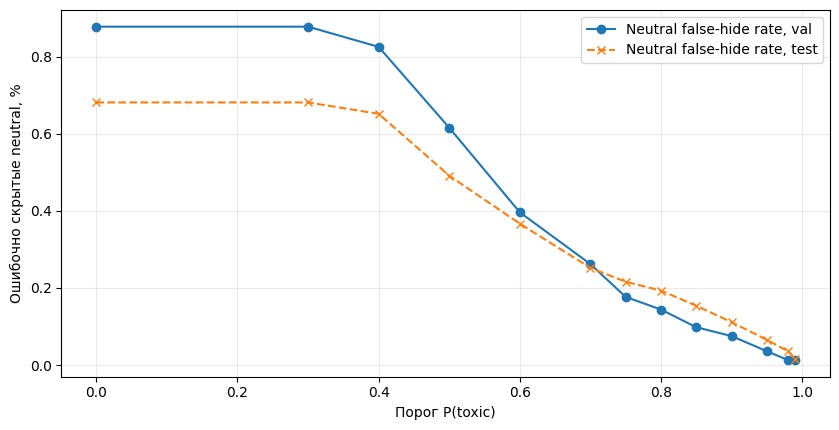

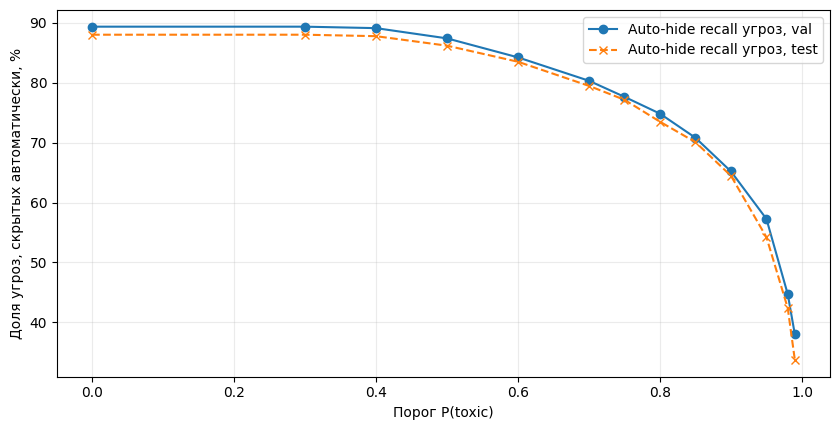

In [8]:
fig, ax=plt.subplots(figsize=(8.5,4.4))
ax.plot(val_thresholds['threshold'],100*val_thresholds['neutral_fpr'], marker='o',label='Neutral false-hide rate, val')
ax.plot(test_thresholds['threshold'],100*test_thresholds['neutral_fpr'], marker='x',linestyle='--',label='Neutral false-hide rate, test')
ax.set_xlabel('Порог P(toxic)'); ax.set_ylabel('Ошибочно скрытые neutral, %')
ax.grid(alpha=.25); ax.legend(); plt.tight_layout();plt.show()
fig, ax=plt.subplots(figsize=(8.5,4.4))
ax.plot(val_thresholds['threshold'],100*val_thresholds['toxic_recall'], marker='o',label='Auto-hide recall угроз, val')
ax.plot(test_thresholds['threshold'],100*test_thresholds['toxic_recall'], marker='x',linestyle='--',label='Auto-hide recall угроз, test')
ax.set_xlabel('Порог P(toxic)'); ax.set_ylabel('Доля угроз, скрытых автоматически, %')
ax.grid(alpha=.25); ax.legend(); plt.tight_layout();plt.show()

### 9.2. Выбор порога на validation — *пример, не действующее правило*

Покажем процедуру на **условном** продуктовым ограничении:

- доля нейтральных комментариев, скрытых автоматически, не более **0,3%** на validation;
- автоматическое скрытие не менее **80%** угроз на validation.

Это лишь иллюстрация процедуры выбора. **Порог 0,3% не согласован с владельцем продукта**, а контроль качества на других источниках данных не проводился. Выберем минимальный порог из проверяемой сетки, удовлетворяющий обоим условиям на validation, и только затем посмотрим результат на test.

In [9]:
MAX_NEUTRAL_FPR_VAL = 0.003
MIN_THREAT_AUTO_RECALL_VAL = 0.80
eligible = val_thresholds[(val_thresholds['neutral_fpr'] <= MAX_NEUTRAL_FPR_VAL) &
                          (val_thresholds['toxic_recall'] >= MIN_THREAT_AUTO_RECALL_VAL)]
if eligible.empty:
    print('На данной сетке нет порога, удовлетворяющего обоим условиям — автоматическое скрытие не предлагается.')
    selected_threshold=None
else:
    selected_threshold=float(eligible.sort_values('threshold').iloc[0]['threshold'])
    print('Выбран порог ТОЛЬКО по validation:',selected_threshold)
    val_pick=val_thresholds[val_thresholds.threshold==selected_threshold].iloc[0]
    test_pick=test_thresholds[test_thresholds.threshold==selected_threshold].iloc[0]
    display(pd.DataFrame([{'split':'validation',**val_pick.to_dict()},
                          {'split':'test',**test_pick.to_dict()}])[show_cols+['split']].round(4))

Выбран порог ТОЛЬКО по validation: 0.7


,threshold,auto_hide_count,neutral_false_hidden,neutral_fpr,toxic_caught,toxic_recall,auto_hide_precision_threat,split
0,0.7,763.0,80.0,0.0026,658.0,0.8034,0.8624,validation
1,0.7,761.0,77.0,0.0025,651.0,0.7949,0.8555,test


**Результат примера:** validation отбирает порог **0,70** (`neutral FPR = 0,262%`, `auto recall угроз = 80,34%`). На test для того же порога получено **77/30 547 = 0,252%** ошибочно скрытых нейтральных и **651/819 = 79,49%** автоматически пойманных угроз. Таким образом, даже если модель выполняет гипотетическую цель по validation, **test recall оказался чуть ниже 80%**: автоматический запуск по такому правилу нельзя одобрять без пересмотра критериев и независимой проверки.

Более строгий пример **0,85**: на test ошибочно скрыто **47 нейтральных из 30 547 (0,154%)**, но автоматически обнаружено **574 из 819 угроз (70,09%)**. Снижение ложных блокировок оплачивается дополнительной работой ручной модерации и риском пропуска угроз без неё.

In [10]:
threshold_compare=pd.DataFrame([
    {'Режим':'Без порога (argmax toxic)',**test_thresholds[test_thresholds.threshold==0.0].iloc[0].to_dict()},
    {'Режим':'Иллюстрация: P(toxic) ≥ 0.70',**test_thresholds[test_thresholds.threshold==0.7].iloc[0].to_dict()},
    {'Режим':'Строже: P(toxic) ≥ 0.85',**test_thresholds[test_thresholds.threshold==0.85].iloc[0].to_dict()},
])
display(threshold_compare[['Режим','auto_hide_count','neutral_false_hidden','neutral_fpr','toxic_caught','toxic_recall','auto_hide_precision_threat']].round(4))

,Режим,auto_hide_count,neutral_false_hidden,neutral_fpr,toxic_caught,toxic_recall,auto_hide_precision_threat
0,Без порога (argmax toxic),1007.0,208.0,0.0068,721.0,0.8803,0.7160
1,Иллюстрация: P(toxic) ≥ 0.70,761.0,77.0,0.0025,651.0,0.7949,0.8555
2,Строже: P(toxic) ≥ 0.85,635.0,47.0,0.0015,574.0,0.7009,0.9039


## 10. Рекомендуемая логика модерации (ещё не интегрирована в API)

Минимально рискованный путь для учебного прототипа — **модерация с участием человека**:

1. `neutral` → оставить опубликованным, но предоставить жалобу пользователя.
2. `offensive` → отправить в очередь проверки или применить отдельные правила платформы; само по себе это не доказательство угрозы.
3. `toxic` с умеренной уверенностью → очередь ручной проверки.
4. `toxic` с высокой уверенностью → потенциально временно скрыть **только если** допустимый риск согласован, проведена проверка порогов, есть аудит, возврат ошибочно скрытого и обжалование.

Следующая функция иллюстрирует **внешнее правило принятия решения по JSON-ответу** и не создаёт реального скрытия в базе или Telegram.

In [11]:
def propose_moderation_action(prediction: dict, threshold: float=0.85) -> str:
    """Демонстрация возможной бизнес-политики; НЕ является кодом текущего API."""
    label=prediction['label']
    prob=prediction['probabilities']
    if label == 'neutral':
        return 'keep'
    if label == 'offensive':
        return 'human_review'
    if label == 'toxic':
        return 'temporary_hide_candidate' if prob['toxic'] >= threshold else 'human_review'
    raise ValueError('Неизвестная метка')

examples=[
 {'label':'neutral','probabilities':{'neutral':0.96,'offensive':0.03,'toxic':0.01}},
 {'label':'offensive','probabilities':{'neutral':0.10,'offensive':0.82,'toxic':0.08}},
 {'label':'toxic','probabilities':{'neutral':0.06,'offensive':0.09,'toxic':0.85}},
 {'label':'toxic','probabilities':{'neutral':0.25,'offensive':0.30,'toxic':0.45}},
]
display(pd.DataFrame([{'label':p['label'],'P(toxic)':p['probabilities']['toxic'],
                        'proposed_action':propose_moderation_action(p)} for p in examples]))

,label,P(toxic),proposed_action
0,neutral,0.01,keep
1,offensive,0.08,human_review
2,toxic,0.85,temporary_hide_candidate
3,toxic,0.45,human_review


## 11. Три экспериментальных варианта и статус развёртывания

В проекте сравнивались **Naive Bayes**, **Logistic Regression** и **Linear SVM (SGD)**. На отдельном офлайн-запуске с `scikit-learn 1.8.0` validation Macro-F1 были соответственно **0,631726**, **0,852941** и **0,838055**. Эти значения **не следует выдавать за результаты финального локального MLflow запуска** под `scikit-learn 1.9.1`: его точные validation-показатели нужно взять из MLflow.

**Подтверждённый финальный MLflow запуск на Mac:** победитель по validation — Logistic Regression, итоговые test Macro-F1 и Recall `toxic` совпали с baseline (**0,857168623** и **0,880341880**). Значит, на этих двух показателях **улучшения нет**. API по-прежнему использует сохранённый baseline; пересчёт порогов выше относится к нему.

Важно: **Macro-F1 и Recall toxic недостаточно** для безусловного обновления правила автоматического скрытия. Нужно сравнивать также `neutral → toxic`, `neutral → offensive`, Precision на действиях, калибровку вероятностей и ручную оценку спорных случаев.

## 12. Реальное применение проекта: путь сообщения и эксплуатационные проверки

```text
Сообщение / HTTP POST /predict
    ↓
Pydantic: проверка формата, длины, наличия букв
    ↓
ModelService: TF-IDF → Logistic Regression → label + probabilities
    ↓
HTTP JSON ответ (НЕ скрывает сообщение)
    ├─→ PostgreSQL: версия модели, класс, confidence, исходный текст
    └─→ Prometheus: агрегированные счётчики и задержки
             ↓
          Grafana: доступность, RPS, p95, распределение классов

Offline: dataset → train/validation/test → три кандидата → MLflow → ручное решение о релизе
```

**Что локально проверено:** Docker Compose запустил API, PostgreSQL, отдельную тестовую БД, MLflow, Prometheus и Grafana; выполнены 13 дополнительных и 19 интеграционных тестов PostgreSQL; Prometheus имел target `toxicity-api` в состоянии **UP**, в Grafana появились реальные показатели после тестовых запросов. Локальный MLflow содержит пять runs. **Что не следует утверждать:** промышленная нагрузка, устойчивость к дрейфу, корректность автоматического удаления и доставка алертов не подтверждены.

Технический контракт: `POST /predict` возвращает `label`, `probabilities`, `model`; `/health/live`, `/health/ready`, `/model-info`, `/metrics` обеспечивают диагностику. Внешний порт на Mac можно задавать через `API_HOST_PORT`; пользователь использовал `18000`.

## 13. Проверка настоящего локального API (необязательно)

Ячейка по умолчанию **не вызывает** API и не отправляет данные. Если FastAPI запущен на Mac, включите `RUN_API_SMOKE=True`. Пример содержит только синтетический тестовый текст; не пересылайте пользовательские комментарии в сторонние сервисы.

In [12]:
RUN_API_SMOKE=False
API_BASE_URL='http://127.0.0.1:18000'
if RUN_API_SMOKE:
    import json as _json
    from urllib.request import Request, urlopen
    with urlopen(API_BASE_URL+'/health/ready',timeout=5) as r:
        print('ready:',r.status,r.read().decode('utf-8'))
    with urlopen(API_BASE_URL+'/model-info',timeout=5) as r:
        print('model-info:',r.status,r.read().decode('utf-8'))
    req=Request(API_BASE_URL+'/predict',
                data=_json.dumps({'text':'Спасибо, хорошего дня!'},ensure_ascii=False).encode(),
                headers={'Content-Type':'application/json'}, method='POST')
    with urlopen(req,timeout=10) as r:
        result=_json.loads(r.read())
    print('predict:',result)
    print('Предлагаемое действие (не выполняется):',propose_moderation_action(result))
else:
    print('API smoke test отключён. Для локального запуска переключите RUN_API_SMOKE=True.')

API smoke test отключён. Для локального запуска переключите RUN_API_SMOKE=True.


## 14. Мониторинг: что измерено, а чего пока нет

| Уровень | Метрики | Реализация |
|---|---|---|
| Доступность | `up{job="toxicity-api"}`, `/health/ready` | Есть; в Prometheus target подтверждён как UP |
| HTTP | `toxicity_http_requests_total`, `toxicity_http_request_duration_seconds` | Есть |
| Инференс | `toxicity_inference_duration_seconds`, p95 | Есть; локально на тестовых запросах p95 около 9,6 мс |
| Распределение прогнозов | `toxicity_predictions_total{source,predicted_class}` | Есть; **не равно реальной точности** |
| Реальный neutral false-hide rate | Сопоставление скрытий с вручную подтверждённой меткой | **Нет**, пока нет механизма скрытия и регулярной разметки |
| Онлайн Recall toxic / precision | Нужны независимые истинные метки | **Нет** в текущих Prometheus-счётчиках |
| Drift текста/языка | Агрегированные свойства текста и разметка по периодам | Запланировано, не реализовано |
| Доля решений `hide/review/keep` | Отдельный счётчик действий модерации | Не реализовано: решения ещё не выполняются |

**Текущие Prometheus-алерты:** API недоступен 2 минуты; более 5% HTTP 5xx на `/predict` в 5-минутном окне в течение 10 минут; p95 инференса более 1 секунды в 5-минутном окне в течение 10 минут. **Маршрут доставки уведомлений (Alertmanager, почта и т. п.) ещё не подтверждён.**

Для оценки риска неверного скрытия нужны размеченные события после апелляций, независимая случайная выборка действий модерации и раздельные оценки по классам и источникам, а не только Prometheus `predicted_class`.

## 15. Ограничения перед внедрением автоматического скрытия

1. **Ошибки нейтрального класса:** при простом скрытии `toxic` — 208 нейтральных случаев на test, при скрытии двух классов — 1 214. Для публичной площадки это непосредственно затрагивает пользователей.
2. **Пропуск угроз:** 98 из 819 `toxic` не получили предсказание `toxic` по baseline. Повышение порога дополнительно сокращает автоматический охват угроз.
3. **Неоднозначная разметка:** 8 333 многометочных строк исключены, модель не проверена на них. Случаи иронии, цитат, контекста и языка могут давать дополнительные ошибки.
4. **Dataset shift и prevalence shift:** в рабочем потоке доли классов могут сильно отличаться от тестовых. При другой распространённости угроз **precision автоматических блокировок изменится**, даже если условные ошибки модели останутся прежними.
5. **Порог и калибровка:** `predict_proba` нуждается в отдельной проверке калибровки; при сравнении порогов необходимо закрепить sklearn и версию артефакта.
6. **Управление последствиями:** нет реализованного механизма скрытия, апелляции, аудита модераторского решения и регулярной проверки качества по ручным меткам.
7. **Приватность:** API сохраняет исходные тексты в PostgreSQL; нужны управление сроками хранения, правами доступа и правила обезличивания.
8. **Оценка вне исходного распределения:** тестовая выборка взята из того же датасета, что и обучение; требуется отдельная новая выборка из реального потока с независимой разметкой.

## 16. Опциональный воспроизводимый пересчёт порогов по исходной модели

При наличии приватного `data/dataset.txt.zip` и baseline-артефакта можно проверить таблицу с нуля. Блок **выключен по умолчанию**, поскольку публичная версия репозитория не содержит датасет. Запускать только на доверенном `joblib` внутри закреплённого окружения проекта (`scikit-learn 1.9.1`); загрузка посторонних `.joblib` небезопасна.

Вход: приватный TXT/ZIP; выход: **только агрегированные числа**, без вывода и экспорта пользовательских сообщений. Все пороги применяются **к validation и test отдельно**, без переобучения модели.

In [13]:
RUN_RECALCULATION=False
if RUN_RECALCULATION:
    import sys, json, warnings, joblib
    from pathlib import Path
    roots=[Path.cwd(),*Path.cwd().parents]
    project_root=next((p for p in roots if (p/'mlops/data.py').is_file() and (p/'artifacts/baseline_model.joblib').is_file()),None)
    if project_root is None:
        raise FileNotFoundError('Откройте проект Team12 с папками mlops/ и artifacts/')
    sys.path.insert(0,str(project_root))
    from mlops.data import read_labeled_dataset, split_like_original, dataset_sha256
    source=project_root/'data/dataset.txt.zip'
    if not source.exists():
        source=project_root/'data/dataset.txt'
    assert source.exists(), 'Локальный датасет не найден'
    assert dataset_sha256(source)==DATASET_SHA256, 'Хеш исходных данных отличается'
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=UserWarning)
        model=joblib.load(project_root/'artifacts/baseline_model.joblib')
    frame,excluded=read_labeled_dataset(source)
    train,val,test=split_like_original(frame,seed=42)
    assert (len(train),len(val),len(test)) == (167930,35985,35985)
    index_toxic=list(model.classes_).index('toxic')
    for split_name,s in [('validation',val),('test',test)]:
        p=model.predict_proba(s.text_clean)
        pred=model.classes_[p.argmax(axis=1)]
        real=s.label.to_numpy()
        n_neutral=(real=='neutral').sum()
        n_toxic=(real=='toxic').sum()
        print('\n',split_name)
        for threshold in [0.0,0.5,0.7,0.85,0.95]:
            auto_hide=(pred=='toxic')&(p[:,index_toxic]>=threshold)
            fpr=np.sum(auto_hide&(real=='neutral'))/n_neutral
            recall_auto=np.sum(auto_hide&(real=='toxic'))/n_toxic
            print(f'th={threshold:.2f}; false-hide neutral={fpr:.4%}; threat auto-recall={recall_auto:.4%}')
else:
    print('Полный пересчёт выключен: сохранены агрегированные результаты, сырые тексты не используются.')

Полный пересчёт выключен: сохранены агрегированные результаты, сырые тексты не используются.


## 17. Финальное заключение

**Подтверждено:** baseline даёт **Accuracy 94,33%, Macro-F1 0,8572, Recall угроз 88,03%** на исходном тесте. Воспроизводимый локальный контур проекта включает HTTP API, тесты с PostgreSQL, три обучаемых алгоритма, MLflow и технический мониторинг. Повторное обучение в локальном MLflow **не показало улучшения** двух итоговых метрик относительно baseline.

**Не подтверждено:** пригодность модели для полностью автоматического и необратимого скрытия комментариев. Даже на исходном test ошибочно скрывались бы **0,68% нейтральных при блокировке только `toxic`** либо **3,97% при блокировке `offensive + toxic`**. Ужесточение порога уменьшает этот риск, но ухудшает автоматический охват угроз. Новые политики пока исследовательские и **не внедрены в API**.

**Применение в текущем качестве:** классификация комментариев, сортировка обращений и помощь модератору. Для автоматической блокировки требуются согласованная цена ошибок, проверка порога в целевой среде, независимая разметка нового трафика, журнал решений без избыточных персональных данных, апелляция и мониторинг фактических ошибок модерации.